Пункт 0: Описание задачи.

Данный датасет ("Mental Health & Burnout Prediction Dataset", автор: Mooben Fatima, Kaggle) содержит синтетические данные (50 000 объектов и 40 признаков), имитирующие демографические, профессиональные, поведенческие, психологические факторы, связанные с психическим здоровьем и профессиональным выгоранием.

Набор данных содержит информацию о: уровне образования, ежемесячном доходе, продолжительности сна, качестве сна, общем количестве времени использования гаджетов (screen_time_hourse) и т.д.

Параметры, которые необходимо определить (предсказать):

-риск профессионального выгорания (Burnout_Risk, категориальный признак):

низкий,
умеренный,
высокий

-состояние психического здоровья (Mental_Health_Status, категориальный признак)

здоров,
требует внимания,
критический уровень

Т.е. данная задача - задача классификации. В данной работе (задании) буду предсказывать риск выгорания.

In [ ]:
import numpy as np #numpy - матричные операции
import matplotlib.pyplot as plt #matplotlib - научная графика
import pandas as pd #pandas - таблицы (DataFrame) для анализа данных
%matplotlib inline
#графики, построенные matplotlib, будут отображаться под ячейками кода в виде статического изображения
#иначе они бы отображались в отдельном окне

In [ ]:
#Пункт 1: прочитать данные
url = "https://raw.githubusercontent.com/vladB77-name/ml_homework_practice2026/refs/heads/main/mental_health_burnout_prediction_dataset.csv"
data = pd.read_csv(url)

In [ ]:
data.shape

(50000, 40)

In [ ]:
data.head(5)[['Person_ID','Age','Country','Remote_Work','Therapy_Attendance','Support_System','Burnout_Score','Mental_Health_Status','Burnout_Risk']]

,Person_ID,Age,Country,Remote_Work,Therapy_Attendance,Support_System,Burnout_Score,Mental_Health_Status,Burnout_Risk
0,1,58.0,United States,Hybrid,Yes,Average,82,Critical,High
1,2,24.0,Pakistan,Hybrid,No,Good,64,Critical,Moderate
2,3,59.0,Malaysia,No,No,Average,50,Needs Attention,Moderate
3,4,65.0,Mexico,Yes,Yes,Good,16,Healthy,Low
4,5,64.0,Japan,No,No,Poor,26,Healthy,Low


'Person_ID', 'Age', 'Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Remote_Work', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Sleep_Quality', 'Stress_Level', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Exercise_Frequency', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk' - полный список столбцов датасета

In [ ]:
#Пункт 2: разбить данные на обучающую и тестовую выборки
import sklearn #алгоритмы машинного обучения

Требуется предсказать признак: Burnout_Risk. Его мы убираем из данных, по которым будем предсказывать данный признак. Также из X убираю признаки:


*   Mental_Health_Status (т.к. это тоже один из признаков, который нужно определять по данному датасету)
*   AI_Wellness_Recommendation (рекомендации для улучшения общего физического и психологического состояни от искусственного интелекта). Данный признак я отношу к текстовым, поэтому убираю на данный момент.
*   Person_ID (т.к. данный признак никак не связан с Burnout_Risk)



In [ ]:
print(len(data['Country'].unique()))

25


Также убираю признак Country, т.к. считаю, что на психологическое состояние человека влияют условия, в которых он проживает (в одной и той же стране могут проживать люди с высоким риском выгорания и низким). Кроме того, данный признак имеет 25 уникальных значений, что при векторизации создаст 25 новых столбцов.

(если я не прав в выборе столбцов, который стоит убрать из X, пожалуйста оставьте комментарий)

In [ ]:
X = data.drop(['Burnout_Risk','Mental_Health_Status','Country','AI_Wellness_Recommendation','Person_ID'], axis=1)
y = data['Burnout_Risk']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state = 42)
N_train,_ = X_train.shape
N_test,_ = X_test.shape
print(N_train,N_test)

37500 12500


Пункт 3:

Визуализировать данные и вычислить основные характеристики (среднее, разброс, корреляционную матрицу и т.д.). Интерпретировать

In [ ]:
X_train[['Age','Work_Hours_Per_Week','Job_Satisfaction', 'Screen_Time_Hours', 'Burnout_Score']].describe()

,Age,Work_Hours_Per_Week,Job_Satisfaction,Screen_Time_Hours,Burnout_Score
count,37310.000000,37500.000000,37112.000000,36856.000000,37500.000000
mean,41.415009,44.987467,5.490596,8.003462,40.272373
std,13.866775,14.711819,2.863501,3.468975,26.193862
min,18.000000,20.000000,1.000000,2.000000,0.000000
25%,29.000000,32.000000,3.000000,5.000000,19.000000
50%,41.000000,45.000000,5.000000,8.000000,39.000000
75%,53.000000,58.000000,8.000000,11.000000,59.000000
max,65.000000,70.000000,10.000000,14.000000,100.000000


Описание некоторых числовых признаков исходя из таблицы выше.

Age: Возраст людей в датасете принимает значения от 18 до 65 лет (люди трудоспособного возраста. Логично для датасета о профессиональном выгорании). Среднее отклонение составляет 13.9 лет.

Work_Hours_Per_Week: Среднее число рабочих часов в неделю равно 44,9 , а медиана данного значения составляет 45 (данные распределены почти симметрично). Большинство людей работают стандартное количество часов в неделю (если было бы большое количество переработок, то среднее было бы заметно выше медианы). Однако квантиль 75% составляет 70 часов в неделю, т.е. 25% людей работает больше 70 часов в неделю (переработки)

Job_Satisfaction (удовлетворенность работой). Минимальное значение - 1, максимальное - 10 (10 бальная шкала). Среднее равно 5.49, медиана 5.0, а стандартное отклонение 2.86. Половина сотрудников оценивает свою работу на 5 баллов и ниже. 25% поставили 3 балла и ниже, уровень недовольства существенный.

Screen_Time_Hours (число часов, проведенное за экраном, в день): Медиана и среднее почти совпадают. Значит данные распределены почти симметрично (т.е. большинство людей проводят примерно 8 часов в день перед экраном (нет тех кто проводит сильно больше/времени этого значения)). 8 часов это довольно много, говорит о высокой цифровой нагрузке.

Burnout_Score (оценка эмоционального выгорания): среднее нескоько выше медианы (есть несколько больших значений). Большое стандартное отклонение (26 баллов). Половина оценивает уровень выгорания в 39 баллов, но 25% оценили его в 59 баллов и выше (т.е. большинство оценивает свой уровень выгорания как низкий и умеренный).

Можно заметить, что в некоторых признаках count меньше чем 37500. Это означает, что в данных столбцах есть незаполненные ячейки.

In [ ]:
some_cut_cols = ['Occupation','Education_Level','Chronic_Stress','Remote_Work','Stress_Level','Smoking'] #вывод некоторых категориальных признаков
X_train[some_cut_cols].describe()

,Occupation,Education_Level,Chronic_Stress,Remote_Work,Stress_Level,Smoking
count,37500,37500,37500,37500,37500,37500
unique,20,5,2,3,3,2
top,Student,PhD,No,No,Low,No
freq,1944,7573,32452,12563,16126,18792


Ocupation (Профессия). Наиболее частая категория - "Student", а не работающие специалисты. Возможно данная категория вносит шум в предсказание профессионального выгорания.

Education_Level (Уровень образования): Самая частая категория — "PhD". Это говорит о том, что синтетические данные сильно смещены в сторону высокообразованных людей. Модель может научиться связывать выгорание именно с академической или высококвалифицированной средой.

Chronic_Stress: абсолютное большинство (32452) отметило отсутствие хранического стресса. Однако 5048 человек отметило обратное (бинарный признак)

В столбце Therapy_Attendance (посещение терапии) также присутствуют пустые ячейки.

In [ ]:
numeric_X_train = X_train.select_dtypes(include=['int64', 'float64'])


In [ ]:
mat_corr = X_train[['Burnout_Score','Work_Hours_Per_Week','Anxiety_Score','Depression_Score','Screen_Time_Hours','Coffee_Cups_Per_Day','Mood_Score','Productivity_Score']]
mat = mat_corr.corr()
mat

,Burnout_Score,Work_Hours_Per_Week,Anxiety_Score,Depression_Score,Screen_Time_Hours,Coffee_Cups_Per_Day,Mood_Score,Productivity_Score
Burnout_Score,1.000000,0.605094,0.923993,0.910513,0.350960,0.268554,-0.917126,-0.893506
Work_Hours_Per_Week,0.605094,1.000000,0.620961,0.610015,-0.002897,0.006901,-0.626618,-0.611274
Anxiety_Score,0.923993,0.620961,1.000000,0.913060,0.361725,0.271042,-0.940131,-0.915927
Depression_Score,0.910513,0.610015,0.913060,1.000000,0.348475,0.265460,-0.921776,-0.898982
Screen_Time_Hours,0.350960,-0.002897,0.361725,0.348475,1.000000,0.002949,-0.364070,-0.356512
Coffee_Cups_Per_Day,0.268554,0.006901,0.271042,0.265460,0.002949,1.000000,-0.272854,-0.264609
Mood_Score,-0.917126,-0.626618,-0.940131,-0.921776,-0.364070,-0.272854,1.000000,0.974252
Productivity_Score,-0.893506,-0.611274,-0.915927,-0.898982,-0.356512,-0.264609,0.974252,1.000000


Посмотрим как коррелируется признак Burnout_Score (оценка эмоционального выгорания) от других признаков. Сильную положительную корреляцию можно видеть от признаков: Work_Hours_Per_Week (число рабочих часов в неделю) - 0.605094, Anxiety_Score (оценка тревожности) - 0.923993, Depression_Score (оценка депрессии) - 0.923993, Screen_Time_Hours (число часов, проведенных за экраном) - 0.350960, Coffe_Cups_Per_Day (потребляемое число коффе за день) - 0.268554.

Интересно, что большое отрицательное значение корреляции наблюдается у признаков: Mood_Score (оценка настроения: чем лучше настроение, тем меньше оценка эмоционального выгорания), Productivity_Score (оценка продуктивности).

Также сильную отрицательную корреляцию имеют признаки: Productivity_Score и Work_Hours_Per_Week (-0.611274). Т.е. чем больше часов человек работает, тем меньше оценка его продуктивности. Чем меньше оценка продуктивности, тем выше оценка эмоционального выгорания.

In [ ]:
import seaborn as sns

<Axes: >

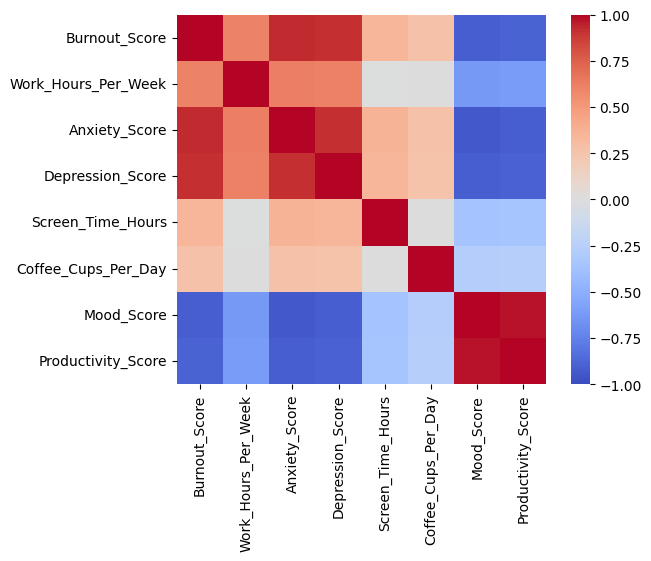

In [ ]:
sns.heatmap(mat,square=True,vmin=-1,vmax=1,cmap='coolwarm') #визуальный образ матрицы корреляции. Чем светлее ячейка, тем больше по абсолютной величине коэффициент корреляции

Пункт 4: разобраться с выбросами. Если они есть

In [ ]:
#проверим есть ли вообще выбросы
numerical_X_train = [c for c in X_train.columns if X_train[c].dtype.name !='object' and c!='Person_ID']
Numeric = X_train[numerical_X_train]
sum = 0
for c in numerical_X_train:
  q1 = Numeric[c].quantile(.25)
  q2=Numeric[c].quantile(.75)
  IQR = q2-q1
  lower_bound = q1 - 1.5*IQR
  upper_bound = q2+1.5*IQR
  if ((Numeric[c]<lower_bound) | (Numeric[c]>upper_bound)).any():
    sum+=1

In [ ]:
print(sum)

0


sum = 0 - считаем, что выбросов нет (any() - проходит по массиву и возвращает True, если нашел хотябы одно True (иначе False))

<Axes: >

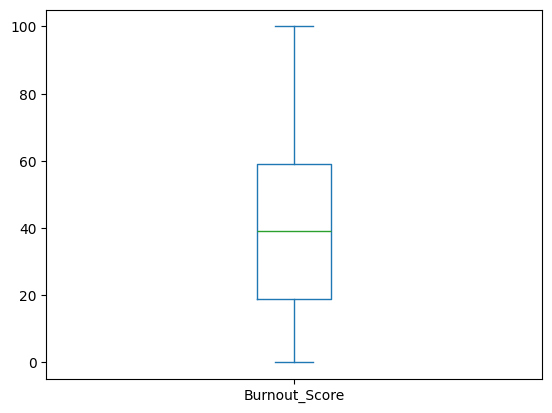

In [ ]:
X_train['Burnout_Score'].plot(kind='box') #пример для признака Burnout_Score (ящик с усами: за пределами усов находятся значения, которые можно считать выбросами)

Пункт 5: Обработать пропущенные значения (или убедиться, что их нет)

In [ ]:
train_na = [c for c in X_train.columns if X_train[c].isna().sum()>0]


In [ ]:
X_train[train_na].isna().sum()

,0
Age,190
Job_Satisfaction,388
Work_Life_Balance,510
Sleep_Hours,707
Anxiety_Score,599
Depression_Score,649
Mood_Score,675
Physical_Activity_Hours,826
Meditation_Minutes,898
Screen_Time_Hours,644


--------------------------
Изначально хотел выбрать из X_train те столбцы, в которых есть пропущенные значения. Позже увидел, что в X_test есть пропуски в столбцах, которые не попали в обучающую выборку. Теперь просто выбираю все числовые и категориальные столбцы

In [ ]:
num_cols = [c for c in numeric_X_train.columns]

In [ ]:
from sklearn.impute import SimpleImputer
imp_num = SimpleImputer(missing_values = np.nan, strategy = 'median')
imp_num.fit(X_train[num_cols])

SimpleImputer(strategy='median')

In [ ]:
X_train[num_cols] = imp_num.transform(X_train[num_cols])

In [ ]:
X_train[train_na].isna().sum()

,0
Age,0
Job_Satisfaction,0
Work_Life_Balance,0
Sleep_Hours,0
Anxiety_Score,0
Depression_Score,0
Mood_Score,0
Physical_Activity_Hours,0
Meditation_Minutes,0
Screen_Time_Hours,0


In [ ]:
category_X_train = [c for c in X_train.columns if X_train[c].dtype.name == 'object']

In [ ]:
X_train['Therapy_Attendance'].describe() #до заполнения пропущенных значений

,Therapy_Attendance
count,37216
unique,2
top,No
freq,18848


In [ ]:
from sklearn.impute import SimpleImputer
imp_cat = SimpleImputer(missing_values=np.nan,strategy='most_frequent')
imp_cat.fit(X_train[category_X_train])

SimpleImputer(strategy='most_frequent')

In [ ]:
X_train[category_X_train]=imp_cat.transform(X_train[category_X_train])

In [ ]:
X_train['Therapy_Attendance'].describe() #после заполнения

,Therapy_Attendance
count,37500
unique,2
top,No
freq,19132


In [ ]:
X_train[train_na].isna().sum()

,0
Age,0
Job_Satisfaction,0
Work_Life_Balance,0
Sleep_Hours,0
Anxiety_Score,0
Depression_Score,0
Mood_Score,0
Physical_Activity_Hours,0
Meditation_Minutes,0
Screen_Time_Hours,0


Пункт 6: обработать категориальные признаки

In [ ]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(drop='if_binary', sparse_output = False) #sparse был переименован в sparse_output (по умолчанию создает разреженную матрицы (равен true))
encoder.fit(X_train[category_X_train])

OneHotEncoder(drop='if_binary', sparse_output=False)

In [ ]:
transform_data = encoder.transform(X_train[category_X_train])
new_names_col = encoder.get_feature_names_out(category_X_train)
index=X_train.index
dummies = pd.DataFrame(transform_data,index,new_names_col)

In [ ]:
dummies.iloc[:5,:7]

,Gender_Female,Gender_Male,Gender_Other,Occupation_Accountant,Occupation_Business Owner,Occupation_Chef,Occupation_Civil Engineer
27434,0.0,0.0,1.0,0.0,0.0,0.0,0.0
13400,0.0,0.0,1.0,0.0,0.0,0.0,0.0
883,0.0,0.0,1.0,0.0,0.0,0.0,0.0
7303,1.0,0.0,0.0,0.0,0.0,0.0,0.0
45124,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
X_train = pd.concat([X_train,dummies],axis=1).drop(category_X_train,axis=1)

In [ ]:
X_train.head(5)[['Sleep_Hours','Smoking_Yes','Chronic_Stress_Yes']] #в качестве примера

,Sleep_Hours,Smoking_Yes,Chronic_Stress_Yes
27434,8.5,1.0,0.0
13400,9.4,0.0,0.0
883,5.7,1.0,0.0
7303,4.4,1.0,1.0
45124,5.5,1.0,0.0


Пункт 7: провести нормализацию (или объяснить, почему в вашем случае она не нужна)

In [ ]:
#нормализуем признаки используя стандартизацию
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train = pd.DataFrame(scaler.transform(X_train), columns = X_train.columns, index = X_train.index)

In [ ]:
X_train[['Age','Work_Hours_Per_Week','Job_Satisfaction', 'Screen_Time_Hours', 'Burnout_Score']].describe()

,Age,Work_Hours_Per_Week,Job_Satisfaction,Screen_Time_Hours,Burnout_Score
count,3.750000e+04,3.750000e+04,3.750000e+04,3.750000e+04,3.750000e+04
mean,1.580247e-16,-2.110786e-16,-5.343281e-17,-8.990734e-16,-3.637979e-17
std,1.000013e+00,1.000013e+00,1.000013e+00,1.000013e+00,1.000013e+00
min,-1.692730e+00,-1.698485e+00,-1.574396e+00,-1.745676e+00,-1.537494e+00
25%,-8.974409e-01,-8.828031e-01,-8.724054e-01,-8.442547e-01,-8.121237e-01
50%,-2.985275e-02,8.519341e-04,-1.704151e-01,-9.894312e-04,-4.857590e-02
75%,8.377354e-01,8.845070e-01,8.825702e-01,8.713539e-01,7.149719e-01
max,1.705324e+00,1.700189e+00,1.584560e+00,1.743697e+00,2.280245e+00


In [ ]:
X_train.shape

(37500, 76)

In [ ]:
X_train.head(5)[['Age','Work_Hours_Per_Week','Job_Satisfaction', 'Screen_Time_Hours', 'Burnout_Score']]

,Age,Work_Hours_Per_Week,Job_Satisfaction,Screen_Time_Hours,Burnout_Score
27434,0.837735,-0.746856,-0.872405,-0.000989,0.600440
13400,-0.969740,1.156401,-0.521410,-0.989645,-0.964833
883,-1.331235,0.272746,1.233565,-0.349927,-0.735769
7303,-0.174451,1.700189,-0.170415,0.725963,2.280245
45124,-0.463647,-1.698485,-1.223400,0.028089,-0.392172


Пункт 8: запустить классификатор (регрессию) ближайших соседей или другой метод (аргументируйте свой выбор!)

In [ ]:
test_na = [c for c in X_test.columns if X_test[c].isna().sum()>0]

In [ ]:
X_test[test_na].isna().sum() #подготовка X_test

,0
Age,60
Monthly_Income_USD,1450
Job_Satisfaction,112
Work_Life_Balance,140
Sleep_Hours,243
Anxiety_Score,201
Depression_Score,201
Mood_Score,225
Physical_Activity_Hours,274
Meditation_Minutes,302


In [ ]:
X_test[num_cols] = imp_num.transform(X_test[num_cols])
X_test[category_X_train] = imp_cat.transform(X_test[category_X_train])

In [ ]:
X_test[test_na].isna().sum()

,0
Age,0
Monthly_Income_USD,0
Job_Satisfaction,0
Work_Life_Balance,0
Sleep_Hours,0
Anxiety_Score,0
Depression_Score,0
Mood_Score,0
Physical_Activity_Hours,0
Meditation_Minutes,0


In [ ]:
dummies_test = pd.DataFrame(encoder.transform(X_test[category_X_train]),columns=encoder.get_feature_names_out(category_X_train),index = X_test.index)

In [ ]:
dummies_test.head(5)[['Gender_Female','Gender_Male','Gender_Other','Occupation_Accountant','Occupation_Chef']]

,Gender_Female,Gender_Male,Gender_Other,Occupation_Accountant,Occupation_Chef
33553,0.0,1.0,0.0,0.0,0.0
9427,0.0,1.0,0.0,0.0,0.0
199,0.0,1.0,0.0,0.0,0.0
12447,0.0,0.0,1.0,0.0,0.0
39489,0.0,0.0,1.0,0.0,0.0


In [ ]:
X_test = pd.concat([X_test,dummies_test],axis=1).drop(category_X_train,axis=1)

In [ ]:
X_test = pd.DataFrame(scaler.transform(X_test),columns = X_test.columns, index = X_test.index)

In [ ]:
X_test.head(5)[['Age','Work_Hours_Per_Week','Job_Satisfaction', 'Screen_Time_Hours', 'Burnout_Score']]

,Age,Work_Hours_Per_Week,Job_Satisfaction,Screen_Time_Hours,Burnout_Score
33553,-1.620431,0.884507,0.882570,-0.204536,0.447730
9427,0.476240,0.544640,-1.574396,0.377026,0.065956
199,0.042446,0.952480,-0.872405,-0.437161,0.218666
12447,-1.403534,0.272746,1.233565,1.481994,0.676795
39489,1.488427,-0.406989,-0.872405,-0.408083,0.371375


Выгорание — сложный процесс. Взаимосвязь между «уровнем образования» и «выгоранием» вряд ли описывается прямой линией (логистическая регрессия). Поэтому использую метод k ближайших соседей (надежда, что данный метод сможет найти зависимость между признаками, даже если данная зависимость не линейная)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 10)
knn.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=10)

In [ ]:
y_train_predict = knn.predict(X_train)
y_test_predict = knn.predict(X_test)

In [ ]:
err_train = 1 - knn.score(X_train, y_train) #процент объектов, классифицированных неправильно (обучающая выборка)

In [ ]:
err_train

0.16661333333333328

In [ ]:
err_test = 1 - knn.score(X_test, y_test) #процент объектов, классифицированных неправильно (тестовая выборка)

In [ ]:
err_test

0.20967999999999998

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
print(knn.classes_) #High - высокий риск выгорания, Low - низкий, Moderate - умеренный

['High' 'Low' 'Moderate']


In [ ]:
print(confusion_matrix(y_test, y_test_predict))

[[1669   25  779]
 [   7 5586  807]
 [ 289  714 2624]]


In [ ]:
print(confusion_matrix(y_train, y_train_predict))

[[ 5320    68  1990]
 [   14 17145  1810]
 [  607  1759  8787]]


Интрепретация матрицы рассогласования (на тестовой выборке)

Класс High:


*   На диагонали (1669): Модель правильно определила 1669 человек как группу высокого риска.
*   Ложноположительные (False Positives) для других классов:

25 человек из группы High модель ошибочно посчитала False

779 человек были отнесены к Moderate.

Вывод: модель плохо справляется с выделением High из Moderate.

Класс Low:


*   Модель правильно определила 5586 человек. Большинство здоровых людей (всего в классе Low: 6400 человек) определены правильно
*   Ложноотрицательные:

7 человек определены в High

807 человек определены в Moderate

Вывод: данные ошибки - ложная тревога (не критичные ошибки)

Класс Moderate:


*   Модель верно определила 2624 человека (всего в данном классе: 3627)
*   Ложноотрицательные ошибки:

модель отнесла 289 человек из Moderate в High (ложная тревога)

*   Ложноположительные:
модель отнесла 714 человек из Moderate в Low (из-за этого состояние  может ухудшиться, риск станет критическим)

Вывод: модель допускает больше всего ошибок в данном классе.













In [ ]:
#некоторые ошибки для High
cm = confusion_matrix(y_test,y_test_predict)
Precession = cm[0][0]/(cm[0][0] + cm[1][0] + cm[2][0]) # из тех, кого отнесли к High, сколько действительно High
Recall = cm[0][0]/(cm[0][0] + cm[0][1] + cm[0][2]) #из тех, кто действительно относится к High, сколько мы обнаружили
print(Precession)
print(Recall)

0.8493638676844784
0.6748887990295188


Почти треть тех, кому срочно нужна помощь, не обнаружены. Если модель определила, что у человека высокий риск выгорания, то скорее всего это верно.

Выбор оптимального значения количества ближайших соседей

GridSearchCV - инструмент, который перебирает заданные параметры модели

knn1 - модель, с которой будем работать

param_grid - словарь (n_neighbors- ключ, nnb - список значений (параметров))

cv - кросс-валидация (10 повторений обучения для всех значений nnb)

grid.best_score_ - лучшая средняя точность, которую удалось достичь в ходе кросс валидации

grid.best_estimator - копия модели knn1, в которую подставлено лучшее число соседей

n_neigbors - обращаемся к лучшему числу соседей


In [ ]:
from sklearn.model_selection import GridSearchCV
nnb = [3, 5, 10, 15, 20, 35, 45, 55]
knn1 = KNeighborsClassifier()
grid = GridSearchCV(knn1, param_grid = {'n_neighbors': nnb}, cv=10)
grid.fit(X_train, y_train)

best_cv_err = 1 - grid.best_score_
best_n_neighbors = grid.best_estimator_.n_neighbors
print(best_cv_err, best_n_neighbors)

0.18973333333333342 55


In [ ]:

nnb2 = [55,65, 75, 85]
knn2 = KNeighborsClassifier()
grid = GridSearchCV(knn2, param_grid = {'n_neighbors': nnb2}, cv=10)
grid.fit(X_train, y_train)

best_cv_err = 1 - grid.best_score_
best_n_neighbors = grid.best_estimator_.n_neighbors
print(best_cv_err, best_n_neighbors)

0.18714666666666668 65


Наилучшее значение количества соседей: 65

Пункт 13: сделать общие выводы

В ходе данной работы я:

*   Работал с Google Colab (впервые)
*   Анализировал данные выбранного датасета
*   Примерно понял как:

Считывать данные csv файла (но только в одном варианте: предоставляя ссылку с репозитория на Github)

Проверять, есть ли в данных выбросы

Обрабатывать пропущенные значения, обрабатывать категориальные признаки (метод векторизации), проводить нормализацию количественных признаков

Запускать классификатор ближайших соседей, вычислять ошибку на обучающей и тестовой выборках, работать с матрицей рассогласования.

Выбирать оптимальное значение количества ближайших соседей.

Модель, обученная на методе ближайших соседей, допускает серьезную ошибку (в количественном плане) в определении самого важного класса: High. Возможно ошибка модели была бы меньше, если бы я не удалил столбцы: Country, AI_Wellness_Recommendation (почему я это сделал, описал ранее)



Вопрос: я обрабатывал данные (заполнение пропущенных значений, векторизация, нормализация) двумя способами. Первый: как на лекции с помощью SimpleImputer, OneHotEncoder, StandardScaler. Второй: как в 19-02. Adult.ipynb, т.е. заполнял пропущенные значения с помощью fillna, применял векторизацию с помощью pandas.get_dummies, нормализовал с помощью формулы. Изначальна работал со вторым способом, но пересмотрел лекцию и решил, что это не верно. Какой из этих способов предпочтительнее? (может, можно использовать только один из них...)

Также изначально я выводил большие таблицы (пример: data.head()), но побоялся, что они некорректно отобразятся в GitHub. Так ли это? (или все отображается корректно?)